# AI Usage & Productivity — Exploratory Data Analysis

**Purpose:** Explore how students and professionals report using AI tools, and how usage relates to time savings, productivity, spending, satisfaction, and willingness to recommend.

**Tools:** Python · Pandas · Matplotlib · Jupyter  
**Dataset:** User-provided CSV (provenance, methodology, and license not independently verified).  
**Design:** Descriptive, cross-sectional analysis; **not** a causal study.

### Questions

1. Which AI tools appear most frequently?
2. How do students and professionals compare?
3. How does daily AI use relate to reported productivity?
4. Which tools are associated with higher reported time savings?
5. Is paying for AI associated with higher satisfaction?
6. How does satisfaction relate to recommendations?

Run the notebook **top to bottom**. Analysis is also reproducible from the command line with `python -m src.analysis`.

## 1 — Import and locate project files

This notebook works if Jupyter starts in the repository root **or** the `notebooks/` directory. The reusable cleaning and chart functions live in `src/analysis.py`.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/analysis.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the repository in VS Code or start Jupyter from its folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis import (
    CLEAN_CSV, FIGURES, REPORTS, read_raw_data, clean_data,
    data_quality_report, generate_charts, user_type_summary,
    tool_time_summary, spending_summary, recommendation_summary,
)

print("Repository:", ROOT.name)

Repository: AI-Usage-Analytics


## 2 — Inspect the raw dataset

Check row/column counts, missing cells, duplicate rows, and inconsistent category labels **before** making changes. This prevents accidentally treating dirty data as reliable.

In [2]:
raw = read_raw_data()
print("Rows, columns:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum())
print("Unique user IDs:", raw["User_ID"].nunique())
display(raw.head(3))

Rows, columns: (300, 19)
Exact duplicate rows: 12
Unique user IDs: 288


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No


In [3]:
print("Missing values in the raw data:")
display(raw.isna().sum().sort_values(ascending=False).rename("Missing").to_frame())
print("Inconsistent tool labels:")
display(raw["AI_Tool"].value_counts(dropna=False).head(18).rename("Respondents").to_frame())
print("Columns represented as text:", raw.select_dtypes(include="object").columns.tolist())

Missing values in the raw data:


,Missing
Age,23
Tasks_Performed,18
Productivity_Score,16
Profession,15
Accuracy_Rating,15
AI_Purpose,13
Education_Level,13
Monthly_AI_Cost,12
AI_Tool,11
Time_Saved_Hours_Per_Week,10


Inconsistent tool labels:


,Respondents
AI_Tool,
ChatGPT,113
Google Gemini,39
Microsoft Copilot,33
Claude,29
Perplexity AI,25
Grammarly,14
NaN,11
DeepSeek,10
Meta AI,10


Columns represented as text: ['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose', 'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Would_Recommend']


## 3 — Clean duplicates, categories, and numeric-looking strings

The `clean_data` function:

- Removes **exact** row duplicates, not all records that share an arbitrary field.
- Standardizes tool aliases (`Chat GPT`/`chatgpt` → `ChatGPT`), gender, country, and education labels.
- Parses known numeric fields (`2 hrs` → `2`, `$20` → `20`) with safe conversion.
- Preserves missing observations as missing and retains unusual observations for inspection.

The raw dataset stays unchanged. Review the function implementation in [`src/analysis.py`](../src/analysis.py).

In [4]:
df = clean_data(raw)
assert len(df) == len(raw) - raw.duplicated().sum()
assert df["User_ID"].is_unique

print(f"Raw rows: {len(raw)} → cleaned rows: {len(df)}")
print("AI tool count after standardization:")
display(df["AI_Tool"].value_counts(dropna=False).rename("Respondents").to_frame())

print("Converted numeric columns:")
display(df[["Age", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost", "Time_Saved_Hours_Per_Week"]].dtypes.to_frame("Data type"))

Raw rows: 300 → cleaned rows: 288
AI tool count after standardization:


,Respondents
AI_Tool,
ChatGPT,119
Google Gemini,39
Microsoft Copilot,33
Claude,31
Perplexity AI,23
Grammarly,14
Meta AI,10
<NA>,10
DeepSeek,9


Converted numeric columns:


,Data type
Age,Int64
AI_Usage_Hours_Per_Day,Float64
Monthly_AI_Cost,Int64
Time_Saved_Hours_Per_Week,Float64


## 4 — Validate data quality and review anomalies

**Cleaning decisions:** No blanket imputation. No arbitrary outlier deletion. Interpret grouped summaries using the number of valid responses (not always 288). Ages over 80, incomes over 20,000, and daily AI hours above 16 are flagged for review—not automatically errors.

In [5]:
quality = data_quality_report(raw, df)
display(quality)
flags = df.loc[
    (df["Age"] > 80) |
    (df["Monthly_Income"] > 20000) |
    (df["AI_Usage_Hours_Per_Day"] > 16),
    ["User_ID", "User_Type", "Age", "Monthly_Income", "AI_Usage_Hours_Per_Day"],
]
print("Potentially unusual rows (review; not removed):")
display(flags)

,Column,Original_Missing,Cleaned_Missing,Cleaned_Missing_Pct,Cleaned_Dtype,Cleaned_Unique
0,User_ID,0,0,0.00,string,288
1,Age,23,23,7.99,Int64,42
2,Gender,10,10,3.47,string,4
3,Country,10,10,3.47,string,12
4,User_Type,0,0,0.00,string,2
5,Education_Level,13,12,4.17,string,6
6,Profession,15,14,4.86,string,126
7,Monthly_Income,10,10,3.47,Int64,231
8,AI_Tool,11,10,3.47,string,8
9,AI_Purpose,13,13,4.51,string,8


Potentially unusual rows (review; not removed):


,User_ID,User_Type,Age,Monthly_Income,AI_Usage_Hours_Per_Day
19,U0046,Professional,61,585,23.0
86,U0248,Professional,97,6779,2.3
200,U0160,Student,17,250000,1.7
210,U0210,Student,97,243,0.8


## 5 — Create reproducible figures

All six charts are regenerated from the cleaned DataFrame and saved under `reports/figures/`. You can independently reproduce them with `python -m src.analysis`.

In [6]:
generate_charts(df)
print("Saved figures to:", FIGURES.relative_to(ROOT))

Saved figures to: reports/figures


## 6 — Q1: Which AI tools are most common?

Use `value_counts()` to count respondents by standardized tool name. These are **counts within this dataset**, not global adoption figures.

,Respondents
AI_Tool,
ChatGPT,119
Google Gemini,39
Microsoft Copilot,33
Claude,31
Perplexity AI,23
Grammarly,14
Meta AI,10
DeepSeek,9


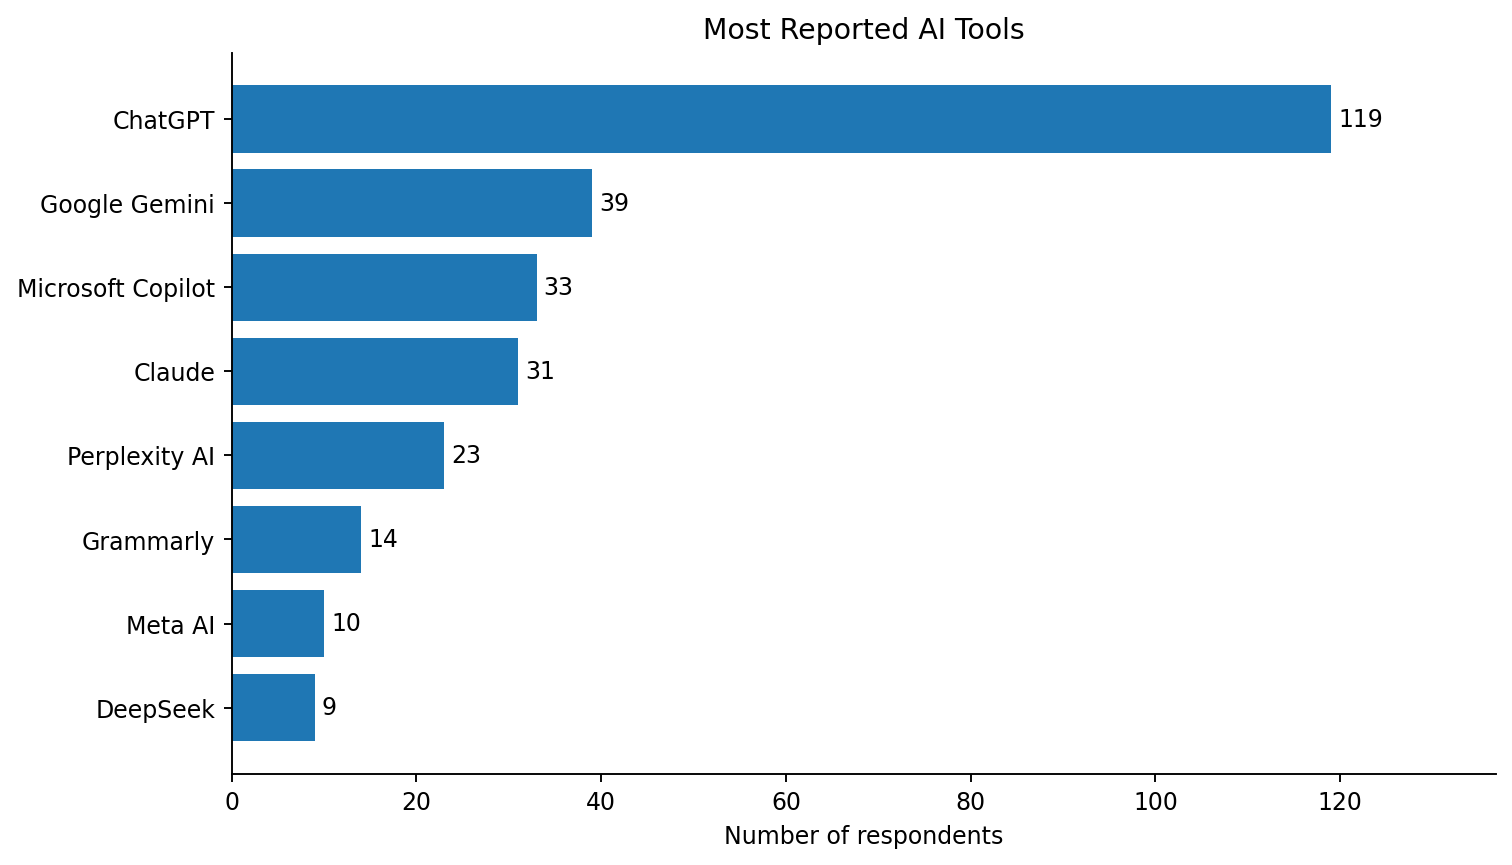

In [7]:
tool_counts = df["AI_Tool"].value_counts()
display(tool_counts.to_frame("Respondents"))
display(Image(filename=str(FIGURES / "01_ai_tool_popularity.png")))

## 7 — Q2: Students vs professionals

Compare respondent counts, median daily AI hours, mean productivity score, and mean reported weekly time savings. Averages use available values; `Valid_Time_Saved` shows the denominator.

,Respondents,Median_Daily_AI_Hours,Mean_Productivity,Mean_Weekly_Time_Saved,Valid_Time_Saved
User_Type,,,,,
Professional,137,2.1,5.28,5.55,130
Student,151,2.0,5.19,6.04,148


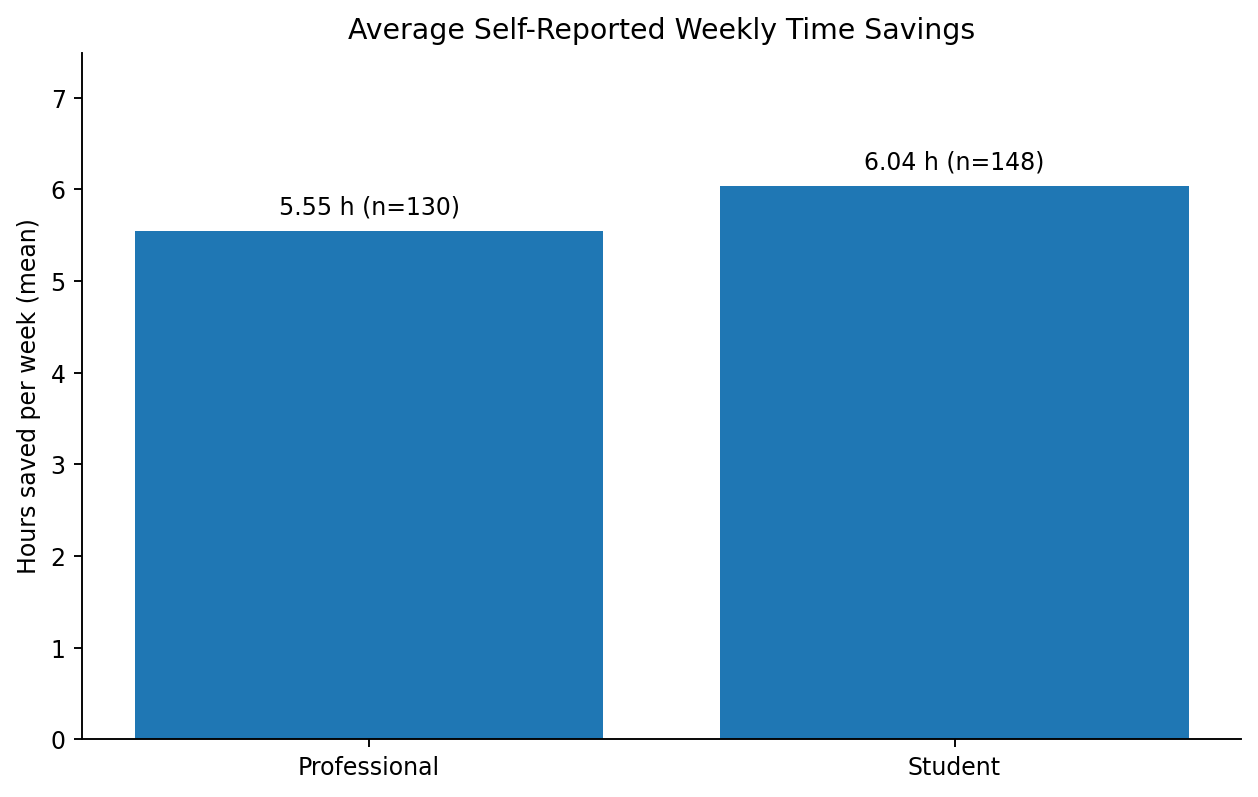

In [8]:
comparison = user_type_summary(df)
display(comparison)
display(Image(filename=str(FIGURES / "02_time_saved_by_user_type.png")))

## 8 — Q3: Daily AI use vs reported productivity

Pearson's correlation summarizes a **linear association**, not an AI-driven productivity gain. A respondent claiming 23 hours of daily AI use is unusually high; compute the coefficient both with and without values over 16 hours to assess sensitivity.

Valid respondent pairs: 267
Pearson r (all available pairs): 0.660
Pearson r (excluding >16 hours/day): 0.781, n=266


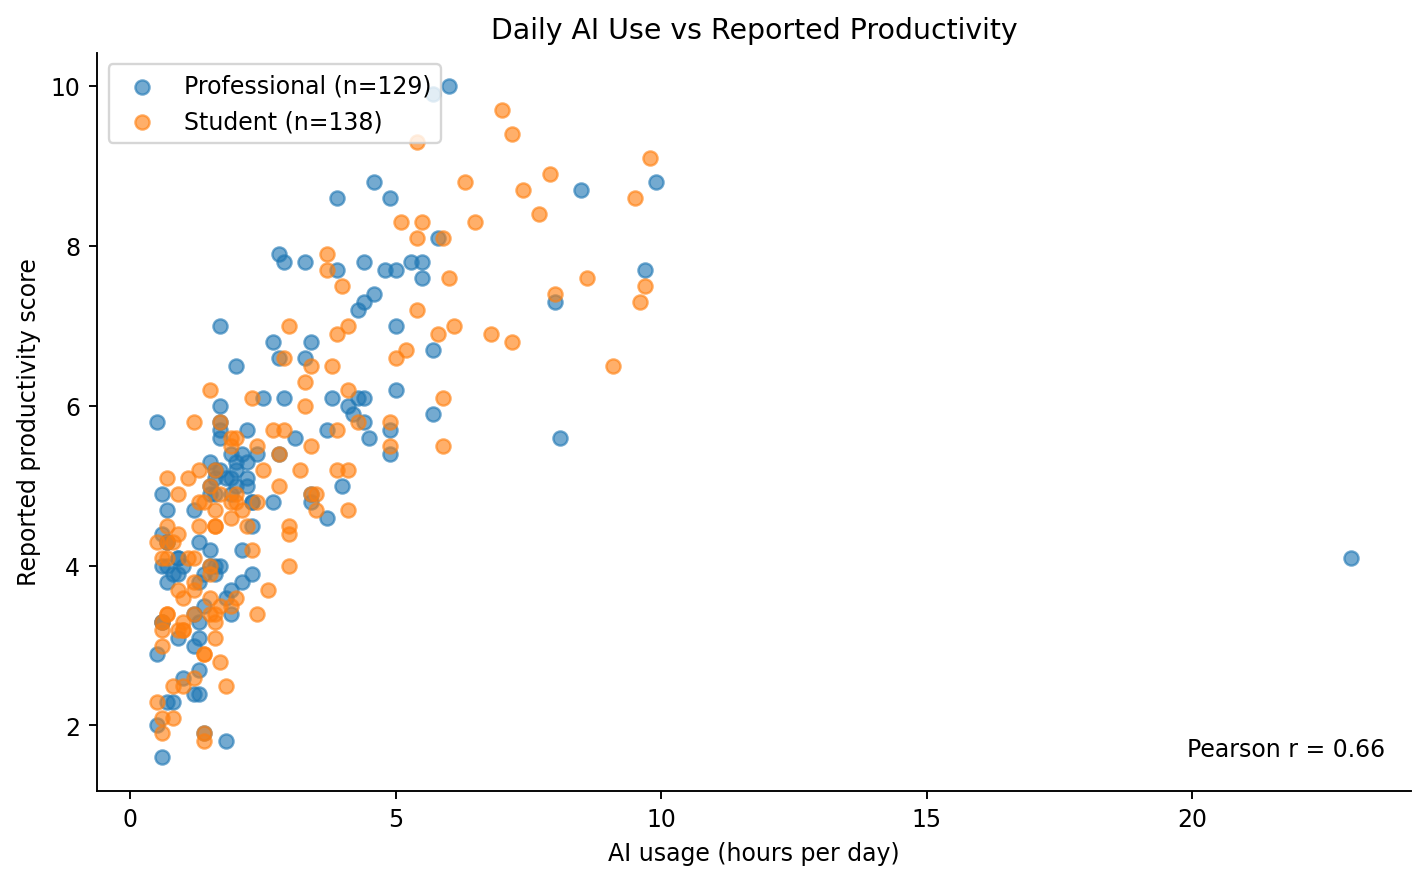

In [9]:
pairs = df[["AI_Usage_Hours_Per_Day", "Productivity_Score"]].dropna()
r_all = pairs["AI_Usage_Hours_Per_Day"].corr(pairs["Productivity_Score"])
no_extreme = pairs[pairs["AI_Usage_Hours_Per_Day"] <= 16]
r_restricted = no_extreme["AI_Usage_Hours_Per_Day"].corr(no_extreme["Productivity_Score"])
print(f"Valid respondent pairs: {len(pairs)}")
print(f"Pearson r (all available pairs): {r_all:.3f}")
print(f"Pearson r (excluding >16 hours/day): {r_restricted:.3f}, n={len(no_extreme)}")
display(Image(filename=str(FIGURES / "03_usage_vs_productivity.png")))

## 9 — Q4: Which AI tools report more weekly time saved?

Use `groupby()` and aggregate **count**, **mean**, and **median**. Tools with at least five valid time-savings responses are shown in the chart so a very small group is not compared uncritically with a large group. The counts still differ, and user characteristics may confound the ranking.

,Valid_Responses,Mean_Hours,Median_Hours
AI_Tool,,,
Microsoft Copilot,32,6.58,6.45
DeepSeek,7,6.56,4.0
ChatGPT,116,5.95,5.2
Perplexity AI,22,5.64,4.2
Claude,29,5.61,4.7
Grammarly,14,5.49,4.2
Google Gemini,38,5.39,4.85
Meta AI,10,4.79,4.2


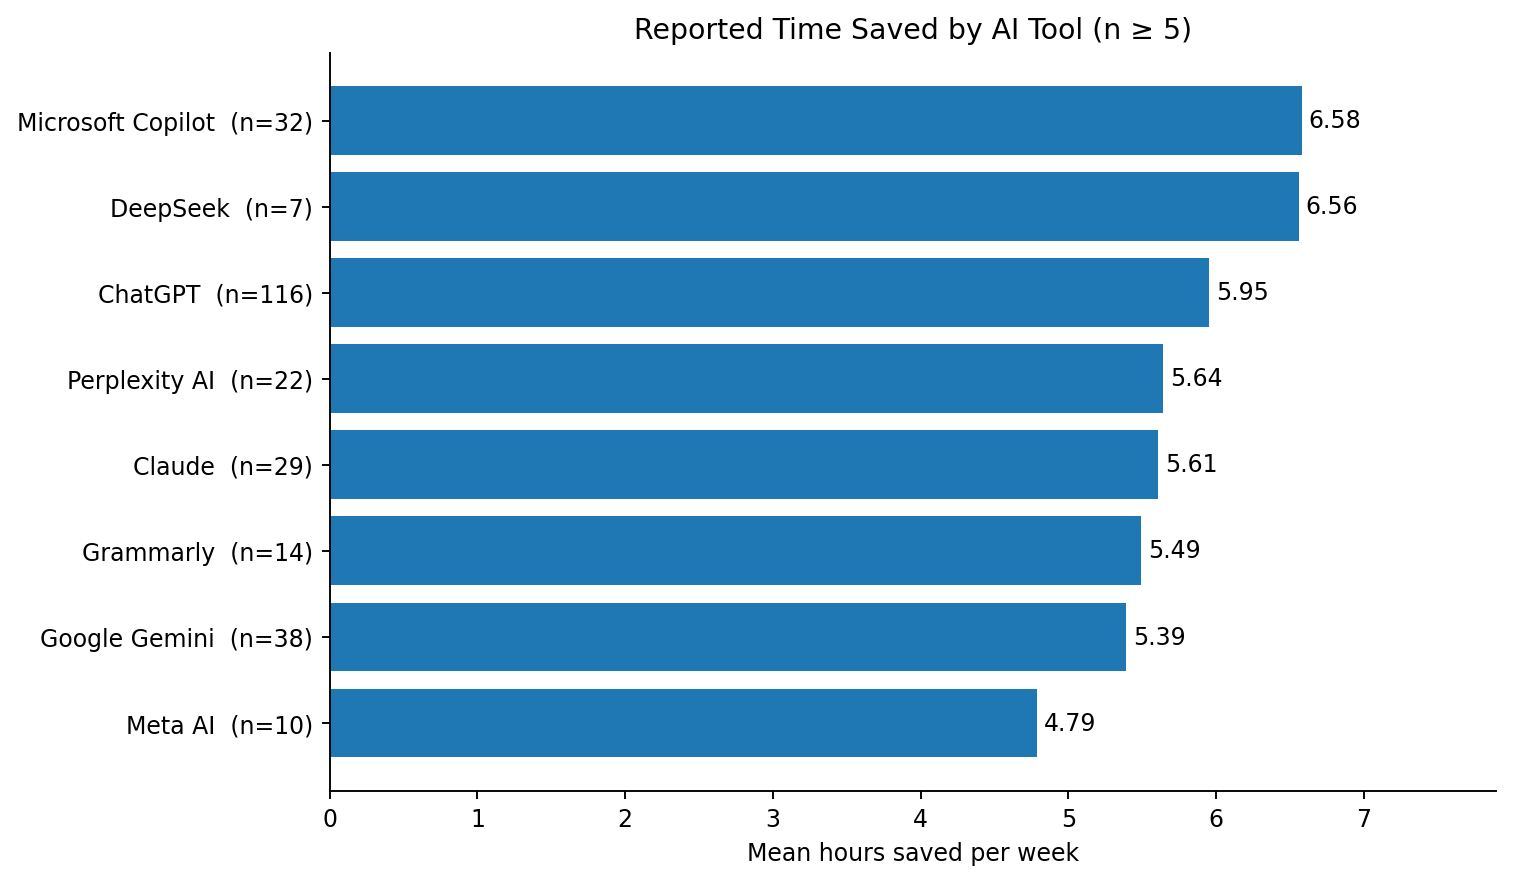

In [10]:
time_by_tool = tool_time_summary(df)
display(time_by_tool)
display(Image(filename=str(FIGURES / "04_time_saved_by_tool.png")))

## 10 — Q5: Does paid AI use coincide with higher satisfaction?

Compare known zero cost with known positive cost. **Missing costs are excluded**, not treated as zero. Currency units are undocumented, so do not compare income or raw spending amounts across countries.

,Valid_Responses,Mean_Satisfaction
Spending_Group,,
No reported cost,142,6.24
Reported cost > 0,127,5.98


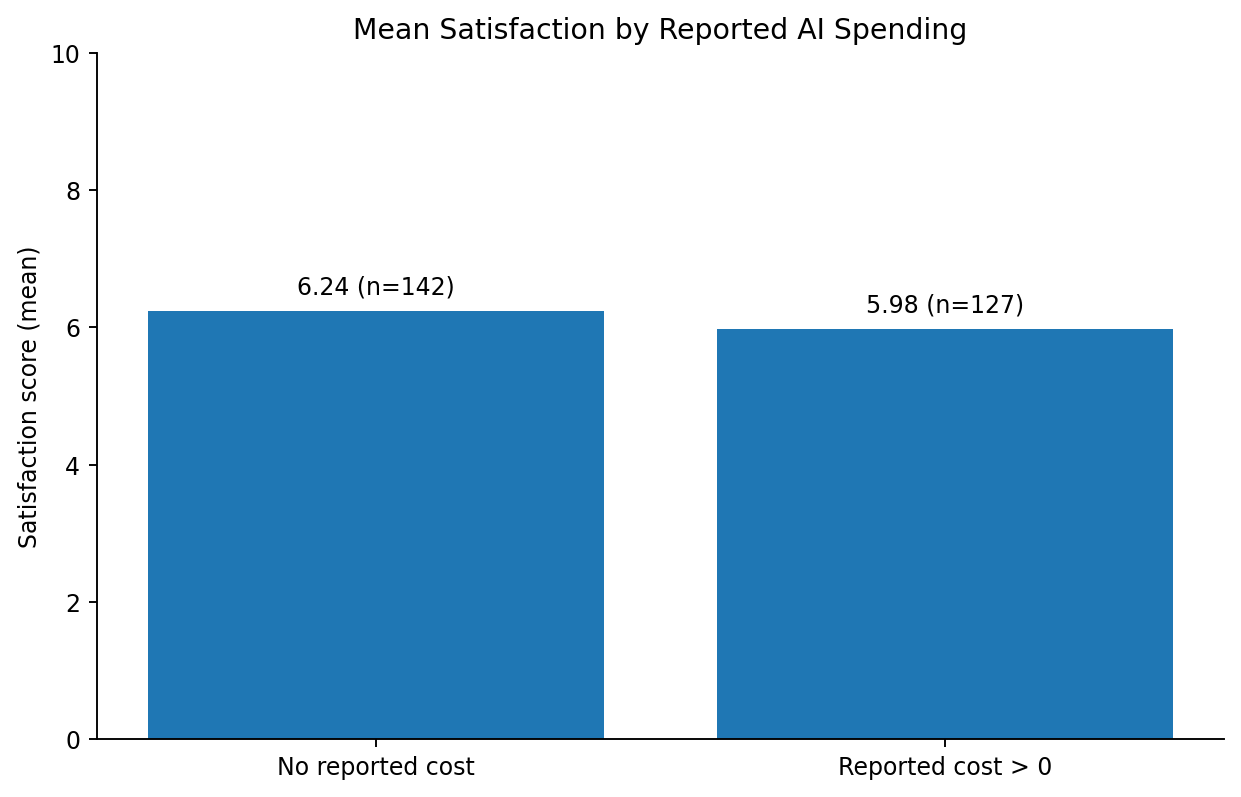

In [11]:
spending = spending_summary(df)
display(spending)
display(Image(filename=str(FIGURES / "05_satisfaction_by_spending.png")))

## 11 — Q6: Are satisfied respondents more likely to recommend?

For interpretation, group satisfaction scores as **low (≤5)**, **moderate (6–7)**, and **high (≥8)**. The chart displays the percentage answering **Yes** among valid responses in each band. These cutoffs are analysis choices, not supplied survey definitions.

,Valid_Responses,Yes_Rate
Satisfaction_Group,,
Low (<=5),97,36.1
Moderate (6–7),130,67.7
High (>=8),49,91.8


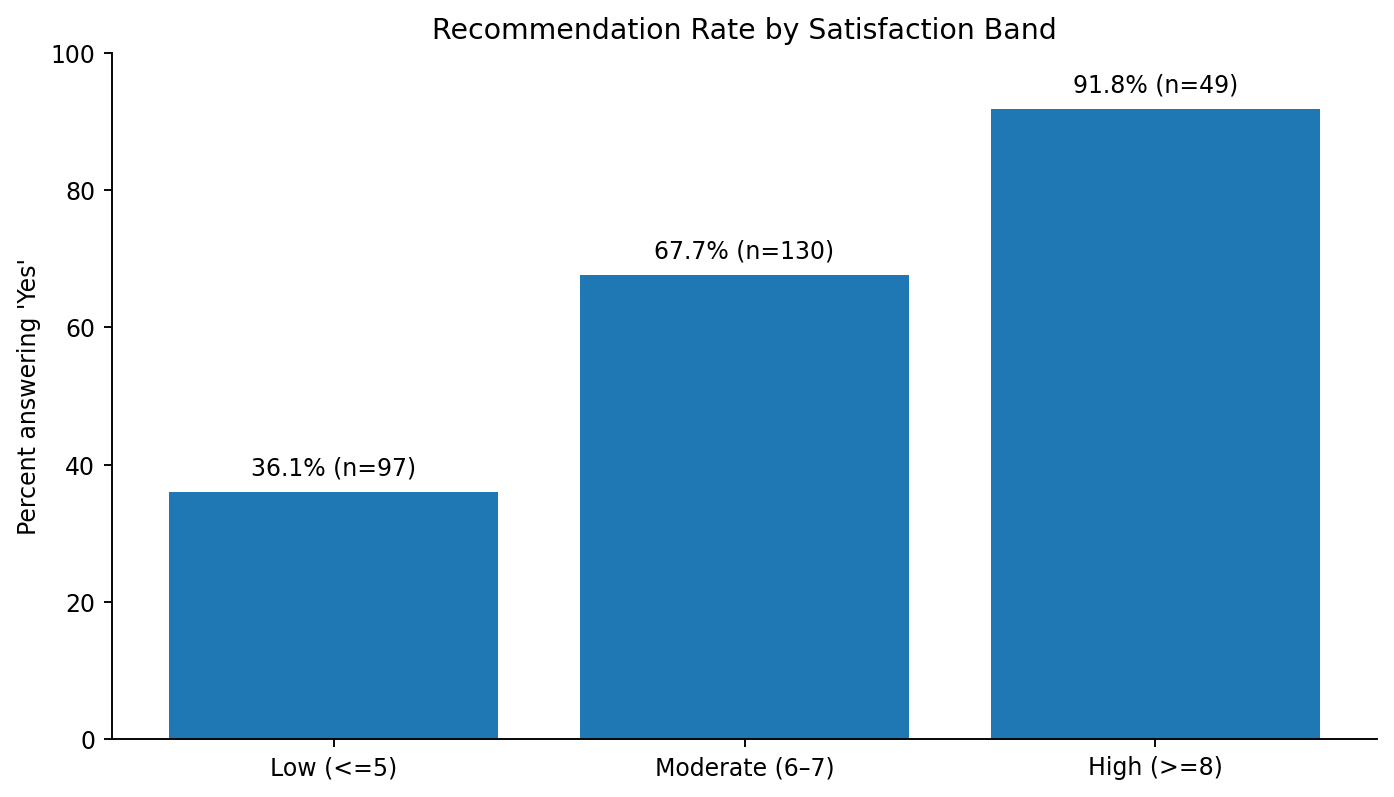

Average satisfaction by recommendation:


,count,mean
Would_Recommend,,
Maybe,40,5.65
No,68,4.96
Yes,168,6.74


In [12]:
recommendation = recommendation_summary(df)
display(recommendation)
display(Image(filename=str(FIGURES / "06_recommendation_by_satisfaction.png")))
print("Average satisfaction by recommendation:")
display(df.groupby("Would_Recommend")["Satisfaction_Score"].agg(["count", "mean"]).round(2))

## 12 — Export outputs

These files are included in the GitHub repository, making the results easy to inspect without running Python. Regenerate them whenever the processing rules change.

In [13]:
CLEAN_CSV.parent.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_CSV, index=False)
quality.to_csv(REPORTS / "data_quality_report.csv", index=False)
print("Cleaned CSV:", CLEAN_CSV.relative_to(ROOT))
print("Quality report:", (REPORTS / "data_quality_report.csv").relative_to(ROOT))
print("Figures:", len(list(FIGURES.glob("*.png"))))

Cleaned CSV: data/processed/AI_Usage_Cleaned.csv
Quality report: reports/data_quality_report.csv
Figures: 6


## 13 — Conclusions and limitations

**Main findings from this supplied sample (after removing 12 exact duplicates):**

- ChatGPT is the most reported tool (**119 of 278 respondents with a known AI tool**).
- Students report an average of **6.04 hours** saved per week (148 valid responses), versus **5.55 hours** for professionals (130 valid responses).
- Daily AI usage and reported productivity have a **positive Pearson correlation of 0.660**, rising to **0.781** when the single >16-hour/day record is excluded. This does **not** prove AI caused productivity gains.
- Microsoft Copilot has the highest mean reported time savings among tools with ≥5 valid reports (**6.58 hours/week**, 32 valid responses). Comparisons across tools are not adjusted for user characteristics.
- Mean satisfaction is **6.24** among respondents reporting zero AI spending, compared with **5.98** among those reporting positive spending. No causal inference follows.
- Answering **Yes** to recommending AI becomes more common at higher satisfaction: **36.1%** in the low band, **67.7%** in the moderate band, and **91.8%** in the high band.

**What this cannot tell us:** The file's sampling method, original data source, score definitions, currency denominations, and representativeness are not documented. This analysis uses self-reported responses and may be affected by selection bias, nonresponse, and confounding. Outliers were retained rather than removed without evidence.

For more on reproducibility, file structure, and interview talking points, see the repository [`README.md`](../README.md).